# 03 · Possession value

What a player's passes and carries are worth. The profiles count actions (progressive passes,
passes into the box); possession value weighs each one by how much closer it takes the ball to a
goal, so that a pass into the six-yard box counts for more than many sideways passes in midfield.

1. **The xT map.** What having the ball in each zone of the pitch is worth: whether the map
   predicts what happened in matches it was not fitted on, which actions it should count, how
   fine its zones should be, and whether one map fits both wings and all four leagues.
2. **Each player's xT.** What a player's passes and carries gain on the map per 90 minutes: how
   to count it (moves that go backwards, passes that fail, balls lost), how much of it is the
   team's possession, and what it adds to the profiles.

**Actions:** open play in the four leagues of the scouting pool (Premier League, La Liga, Serie A
and Ligue 1, 2015/16). Carried over from `01_data_exploration.ipynb`: event locations share one
scale across leagues (section 6), and xG is StatsBomb's as published (section 5).

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events). Only aggregated
results are shown, as StatsBomb's licence requires. Tables are built by `make model`; see
`docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm
from mplsoccer import Pitch
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

from football_scouting.analysis.leagues import league_effect, team_effect
from football_scouting.analysis.metrics import LABELS, ON_BALL, SUMMED, player_match_counts
from football_scouting.analysis.players import pool_player_seasons
from football_scouting.analysis.possession import adjust, elasticity, player_possession
from football_scouting.analysis.profiles import (
    POSSESSION,
    RELIABILITY_MINUTES,
    adjusted_rates,
    compared_players,
    own_share,
    recording_context,
    rescale,
)
from football_scouting.analysis.reliability import split_half_reliability
from football_scouting.analysis.xt import (
    CREDITS,
    LENGTH,
    POOL,
    WIDTH,
    chain_outcomes,
    credit_rates,
    fit,
    load_actions,
    move_credit,
    player_match_credit,
    value_at,
    zones,
)
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
STATSBOMB = "Data: StatsBomb Open Data (2015/16)"
NX, NY = cfg.xt.nx, cfg.xt.ny

actions = load_actions(con, losses=True).merge(
    chain_outcomes(con), on=["match_id", "event_index", "team_id"], how="left", validate="1:1"
)
league = con.sql(
    "SELECT match_id, c.competition_name AS league FROM matches m "
    "JOIN competitions c USING (competition_id, season_id) WHERE m.scouting_pool"
).df()
actions = actions.merge(league, on="match_id", validate="m:1")
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
print(
    f"{actions.match_id.nunique():,} matches, {len(actions):,} open-play actions: "
    + ", ".join(
        f"{n:,} {dict(move='moves', loss='losses', shot='shots')[k]}"
        for k, n in actions.kind.value_counts().items()
    )
    + "."
)

1,517 matches, 2,577,884 open-play actions: 2,434,360 moves, 107,792 losses, 35,732 shots.


## 1. The xT map

Expected threat (xT; Karun Singh, 2018) cuts the pitch into zones. From each zone a team shoots,
moves the ball on (a pass or a carry) or gives it away. The xT of a zone is the xG of the shots
taken there plus the xT of the zones its successful moves reach, each weighted by how often it
happens; a failed move ends the chain with nothing. A move is then worth the xT it gains,
xT(end) − xT(start) (`analysis.xt`).

Only open play counts. A set piece's value comes from the routine, not from the zone it starts
in, so corners, free kicks, throw-ins, goal kicks and kick-offs, and shots straight from them,
are left out; what follows them in open play stays. Dribbles move the ball through the carry
recorded with them.

Every map is checked against what happened in matches it was not fitted on. Each action's
outcome is the xG of the open-play shot its team's chain went on to take (0 if none), where a
chain ends at the opponent's next action on the ball, a set piece or the end of the half
(`chain_outcomes`). A map fitted on half of the matches predicts the outcomes of the other half:
**skill** is the share of a flat guess's squared error (the training half's mean) that the map
removes, and **level** the mean predicted over the mean observed (1 when the map is right on
average). Outcomes are mostly 0 and now and then a large xG, so skill is small for any map; what
counts is how it compares between maps.

### 1.1 The actions

The actions the map is built from, and what comes after them.

In [2]:
on_ball = ", ".join(f"'{t}'" for t in [*ON_BALL, "Goal Keeper"] if t != "Ball Receipt*")
# The next action on the ball after each event: the same team's, in open play?
kept = con.sql(f"""
    SELECT e.match_id, e.event_index,
           lead(e.team_id) OVER w = e.team_id
           AND NOT coalesce(lead(p.pass_type NOT IN ('Recovery', 'Interception')) OVER w, FALSE)
           AS kept
    FROM events e LEFT JOIN passes p USING (event_id, match_id)
    WHERE e.{POOL} AND e.type IN ({on_ball})
    WINDOW w AS (PARTITION BY e.match_id ORDER BY e.event_index)
""").df()
acts = actions.merge(kept, on=["match_id", "event_index"], how="left", validate="1:1")
acts["row"] = np.select(
    [
        (acts.type == "Pass") & acts.success.fillna(False),
        acts.type == "Pass",
        acts.type == "Carry",
        acts.type == "Shot",
    ],
    ["Passes, completed", "Passes, failed", "Carries", "Shots"],
    default=acts.type.map(
        {"Dispossessed": "Dispossessed", "Miscontrol": "Miscontrols", "Dribble": "Failed dribbles"}
    ),
)
ROWS = [
    "Passes, completed", "Passes, failed", "Carries", "Shots", "Dispossessed", "Miscontrols",
    "Failed dribbles",
]  # fmt: skip
table = acts.groupby("row").agg(
    actions=("kind", "size"),
    kept=("kept", "mean"),
    outcome=("outcome", "mean"),
    own_half=("x", lambda x: (x < LENGTH / 2).mean()),
)
table = table.loc[ROWS].rename_axis(index=None)
table.columns = ["Actions", "Same team next", "Chain's xG", "In own half"]
display(
    table.style.format(
        {
            "Actions": "{:,}",
            "Same team next": "{:.1%}",
            "Chain's xG": "{:.4f}",
            "In own half": "{:.0%}",
        }
    ).set_caption(
        "Open-play actions: how many, how often the next action on the ball is the same team's in "
        "open play, the mean xG of the shot their chain leads to, the share in the own half"
    )
)

,Actions,Same team next,Chain's xG,In own half
"Passes, completed","1,021,195",99.9%,0.0092,54%
"Passes, failed","295,969",0.4%,0.0000,48%
Carries,"1,117,196",97.5%,0.0083,50%
Shots,"35,732",0.9%,0.0941,0%
Dispossessed,"39,944",19.9%,0.0016,28%
Miscontrols,"44,606",6.6%,0.0009,25%
Failed dribbles,"23,242",16.9%,0.0014,24%


- A failed pass gives the ball away: the opponent, or a set piece, comes next almost every time
  (StatsBomb marks a pass incomplete when no teammate receives it). After a completed pass or a
  carry the team almost always plays on.
- The textbook model counts only shots and moves, but 107,792 other actions also give the ball
  away: being dispossessed, a miscontrol, a failed dribble. The opponent or a set piece comes
  next after 80% to 93% of them, and three quarters happen in the opponent's half, where chains
  are worth the most.
- A completed pass leads on average to 0.009 xG; a shot's chain ends with the shot (0.094).

### 1.2 The textbook map, and what it leaves out

The textbook map (16 × 12 zones of 7.5 × 6.7 yards, shots and moves only) against the same
model with losses counted as actions that end the chain, like a failed move, and against the
plainest estimate: each zone's mean outcome in the training half (zone average).

In [3]:
GRIDS = [(12, 8), (16, 12), (24, 16), (30, 20), (48, 32), (60, 40)]
MODELS = ["Shots and moves", "With losses", "Zone average"]
DRAWS = 20
outcome = actions.outcome.to_numpy()
is_loss = (actions.kind == "loss").to_numpy()
moved = ((actions.kind == "move") & actions.success.fillna(False)).to_numpy()
matches = np.sort(actions.match_id.unique())
rng = np.random.default_rng(2015)
held_out, calibration = [], []
for draw in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2]).to_numpy()
    test = ~train
    flat = np.mean((outcome[test] - outcome[train].mean()) ** 2)
    for nx, ny in GRIDS:
        z = zones(actions.x, actions.y, nx, ny)
        n_zone = np.bincount(z[train], minlength=nx * ny)
        maps = {
            "Shots and moves": fit(actions[train & ~is_loss], nx, ny).ravel(),
            "With losses": fit(actions[train], nx, ny).ravel(),
            "Zone average": np.bincount(z[train], weights=outcome[train], minlength=nx * ny)
            / np.maximum(n_zone, 1),
        }
        # The same map from the other half: how much the credit of each move depends on the half.
        other = fit(actions[test], nx, ny)
        c1 = move_credit(maps["With losses"].reshape(ny, nx), actions)[moved]
        c2 = move_credit(other, actions)[moved]
        for model, m in maps.items():
            pred = m[z[test]]
            held_out.append({
                "draw": draw, "grid": f"{nx} x {ny}", "model": model,
                "skill": 1 - np.mean((outcome[test] - pred) ** 2) / flat,
                "level": pred.mean() / outcome[test].mean(),
                "fewest": n_zone.min(),
                "credit_r": np.corrcoef(c1, c2)[0, 1] if model == "With losses" else np.nan,
            })  # fmt: skip
            if (nx, ny) in [(16, 12), (NX, NY)] and model != "Zone average":
                bins = pd.qcut(pd.Series(pred).rank(method="first"), 20, labels=False)
                calibration.append(
                    pd.DataFrame({"pred": pred, "obs": outcome[test], "bin": bins})
                    .groupby("bin").mean().assign(draw=draw, grid=f"{nx} x {ny}", model=model)
                )  # fmt: skip
held_out = pd.DataFrame(held_out)
calibration = pd.concat(calibration).groupby(["grid", "model", "bin"])[["pred", "obs"]].mean()

singh = fit(actions[~is_loss], 16, 12)
with_losses = fit(actions, 16, 12)
summary = held_out[held_out.grid == "16 x 12"].groupby("model")[["skill", "level"]].mean()
display(
    summary.loc[MODELS]
    .rename_axis(index=None)
    .style.format({"skill": "{:.4f}", "level": "{:.2f}"})
    .set_caption(
        f"16 x 12 zones, fitted on half of the matches and checked on the other half "
        f"({DRAWS} draws): skill (share of a flat guess's squared error removed) and level "
        "(mean predicted over mean observed)"
    )
)
c_singh = move_credit(singh, actions)[moved]
c_losses = move_credit(with_losses, actions)[moved]
ratio = with_losses / singh
print(
    "Moves' credit, textbook against with losses: "
    f"Pearson {np.corrcoef(c_singh, c_losses)[0, 1]:.3f}, "
    f"Spearman {pd.Series(c_singh).corr(pd.Series(c_losses), method='spearman'):.3f}. "
    f"With losses, xT is {ratio[:, : 16 // 2].mean():.2f} times the textbook's in the own half "
    f"and {ratio[4:8, -1].mean():.2f} times in front of goal."
)

,skill,level
Shots and moves,0.0809,1.46
With losses,0.0915,0.87
Zone average,0.0926,1.01


Moves' credit, textbook against with losses: Pearson 0.996, Spearman 0.990. With losses, xT is 0.48 times the textbook's in the own half and 0.89 times in front of goal.


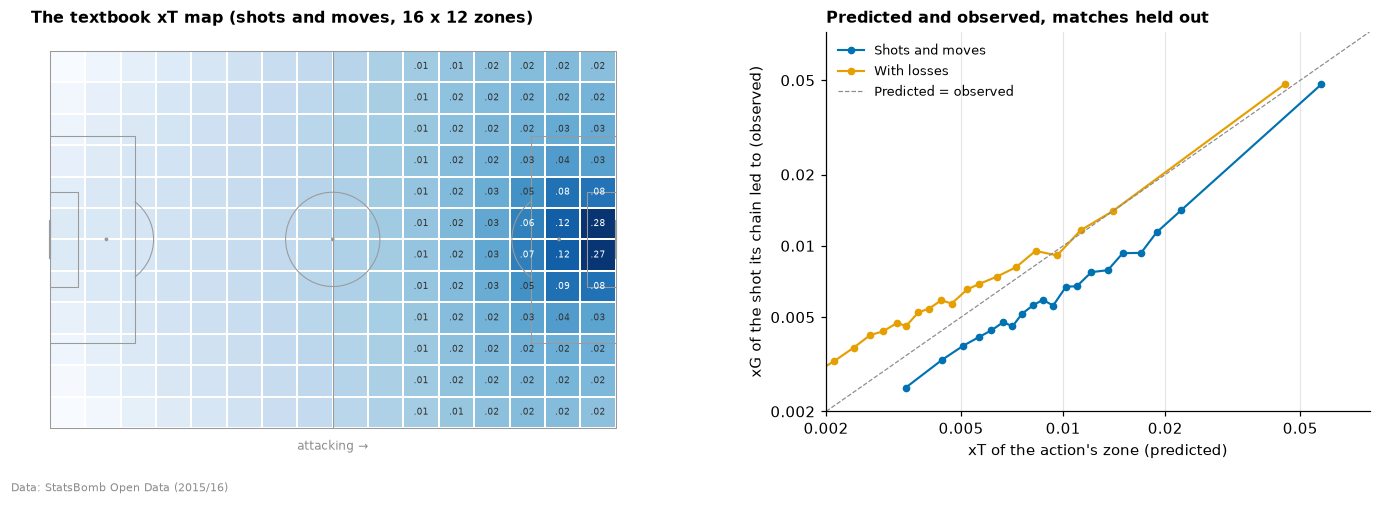

In [4]:
pitch = Pitch(pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=2)
fig = plt.figure(figsize=(13, 4.6))
ax_map = fig.add_axes([0.0, 0.05, 0.47, 0.82])
ax_cal = fig.add_axes([0.58, 0.12, 0.38, 0.75])
stat = pitch.bin_statistic(actions.x, actions.y, statistic="count", bins=(16, 12))
stat["statistic"] = singh
pitch.draw(ax=ax_map)
pitch.heatmap(stat, ax=ax_map, cmap="Blues", norm=LogNorm(0.002, 0.3), edgecolors="white", lw=0.3)
for (row, col), v in np.ndenumerate(singh):
    if col >= 10:
        ax_map.text(
            stat["cx"][row, col], stat["cy"][row, col], f"{v:.2f}".lstrip("0"), ha="center",
            va="center", fontsize=6, color="white" if v > 0.05 else "#333333",
        )  # fmt: skip
ax_map.set_title("The textbook xT map (shots and moves, 16 x 12 zones)", fontsize=10.5)
ax_map.text(60, 82.5, "attacking →", ha="center", va="top", fontsize=8, color=GREY)
for model, color in zip(["Shots and moves", "With losses"], OKABE_ITO, strict=False):
    c = calibration.loc[("16 x 12", model)]
    ax_cal.plot(c.pred, c.obs, "o-", color=color, ms=4, lw=1.4, label=model)
lims = [0.002, 0.08]
ax_cal.plot(lims, lims, color=GREY, lw=0.8, ls="--", label="Predicted = observed")
ax_cal.set(
    xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="xT of the action's zone (predicted)",
    ylabel="xG of the shot its chain led to (observed)",
)  # fmt: skip
ticks = [0.002, 0.005, 0.01, 0.02, 0.05]
ax_cal.set_xticks(ticks, labels=[f"{t:g}" for t in ticks])
ax_cal.set_yticks(ticks, labels=[f"{t:g}" for t in ticks])
ax_cal.minorticks_off()
ax_cal.set_title("Predicted and observed, matches held out", fontsize=10.5)
ax_cal.grid(axis="both")
ax_cal.legend(loc="upper left", fontsize=8.5)
credit(fig, STATSBOMB)
plt.show()

- **The textbook map overstates what happens by 46%.** Its chains run on through the
  dispossessions, miscontrols and failed dribbles it does not see. Counting them turns the map
  13% low, partly because a loss does not always end the chain (one dispossession in five), and
  lifts its held-out skill from 0.081 to 0.092, level with the zone average (0.093). In the
  calibration plot the textbook map sits below the line everywhere; with losses the final third
  is on it and the deep zones a little above.
- Losses keep the map's shape and change the weight of the build-up. xT in the own half halves
  (0.48 times the textbook's) while in front of goal it barely moves (0.89 times). The order of
  moves by credit hardly changes (Spearman 0.990), but a move in the own half now earns about
  half as much as before against one near the box.

### 1.3 How fine the zones should be

Finer zones tell a shot from the penalty spot from one at the edge of the six-yard box, but each
zone has fewer actions to learn from. Six grids, from 10-yard to 2-yard zones, on the same draws:
held-out skill, the gain of each grid over the coarser one before it (paired by draw), and how
much a move's credit depends on which half of the matches the map was fitted on (correlation of
every successful move's credit between the maps of two halves).

In [5]:
size = pd.Series({f"{nx} x {ny}": f"{LENGTH / nx:.1f} x {WIDTH / ny:.1f}" for nx, ny in GRIDS})
by_grid = held_out.pivot_table(index="grid", columns="model", values="skill", sort=False)
gain = (
    held_out[held_out.model == "With losses"].pivot(index="draw", columns="grid", values="skill")
    [size.index].diff(axis=1)
)  # fmt: skip
low, high = gain.quantile(0.025), gain.quantile(0.975)
losses = held_out[held_out.model == "With losses"].groupby("grid", sort=False)
grids = pd.DataFrame({
    "Zone (yards)": size,
    "Fewest actions in a zone": losses.fewest.min(),
    "Skill: with losses": by_grid["With losses"],
    "Skill: shots and moves": by_grid["Shots and moves"],
    "Skill: zone average": by_grid["Zone average"],
    "Gain on the coarser grid": gain.mean(),
    "95% range": (low.map("{:+.4f}".format) + " to " + high.map("{:+.4f}".format)).where(
        low.notna(), ""
    ),
    "Credit, half against half": losses.credit_r.mean(),
}).loc[size.index].rename_axis(index=None)  # fmt: skip
display(
    grids.style.format(
        {c: "{:.4f}" for c in grids.columns if c.startswith(("Skill", "Gain", "Credit"))}
        | {"Fewest actions in a zone": "{:,}"},
        na_rep="",
    ).set_caption(
        f"Held-out skill by grid ({DRAWS} draws of half the matches); gain of each grid on the "
        "one above it, the same draws; correlation of moves' credit between maps of two halves"
    )
)

,Zone (yards),Fewest actions in a zone,Skill: with losses,Skill: shots and moves,Skill: zone average,Gain on the coarser grid,95% range,"Credit, half against half"
12 x 8,10.0 x 10.0,"2,212",0.0800,0.0686,0.0810,,,0.9992
16 x 12,7.5 x 6.7,742,0.0915,0.0809,0.0926,0.0115,+0.0109 to +0.0123,0.9986
24 x 16,5.0 x 5.0,242,0.0963,0.0854,0.0973,0.0048,+0.0029 to +0.0059,0.9968
30 x 20,4.0 x 4.0,102,0.0984,0.0880,0.0993,0.0021,+0.0009 to +0.0033,0.9951
48 x 32,2.5 x 2.5,13,0.1017,0.0915,0.1020,0.0034,+0.0022 to +0.0043,0.9882
60 x 40,2.0 x 2.0,2,0.1022,0.0917,0.1017,0.0004,-0.0004 to +0.0013,0.9812


- Skill rises with every finer grid down to zones of 2.5 yards (48 × 32: 0.102, against 0.092 at
  the textbook's 16 × 12). At 2 yards (60 × 40) the gain stops (+0.0004, with a range from
  −0.0004 to +0.0013).
- A move's credit barely depends on the matches: 0.988 between the maps of two halves at
  2.5 yards, 0.999 at 10 yards.
- Counting losses is better at every grid. The chain keeps up with the zone average down to
  2.5 yards and passes it at 2 yards, where a zone can hold as few as two actions in half a
  season.
- **The map uses 48 × 32 zones of 2.5 × 2.5 yards** (`xt` in `config/pipeline.yaml`).

### 1.4 One map for both wings and all four leagues

One map for the whole pool assumes that a zone is worth the same on either wing and in every
league, and that a shot is best valued by its xG. Three checks, at 48 × 32 zones:

- **Left and right:** each zone's xT against its mirror image across the pitch, next to the
  difference between the maps of two halves of the matches (action-weighted mean absolute
  difference over the mean xT).
- **Leagues:** each league's own map against the pooled one, next to 50 random sets of 380
  matches: level (the mean xT of the league's actions under its own map, over the pooled map's)
  and the correlation of its moves' credit.
- **Goals:** shots valued by whether they were scored instead of their xG.

In [6]:
xt_map = fit(actions, NX, NY)
weight = np.bincount(zones(actions.x, actions.y, NX, NY), minlength=NX * NY).reshape(NY, NX)


def gap(a, b):
    """Action-weighted mean absolute difference between two maps, over the map's mean."""
    return np.sum(weight * np.abs(a - b)) / np.sum(weight * xt_map)


def credit_r(a, b, rows):
    ca, cb = move_credit(a, rows), move_credit(b, rows)
    ok = ~np.isnan(ca)
    return np.corrcoef(ca[ok], cb[ok])[0, 1]


def level(m, rows):
    """Mean xT of the rows' zones under map m, over the pooled map's."""
    return value_at(m, rows.x, rows.y).mean() / value_at(xt_map, rows.x, rows.y).mean()


rng = np.random.default_rng(16)
halves = []
for _ in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2])
    halves.append((fit(actions[train], NX, NY), fit(actions[~train], NX, NY)))
print(
    "Left against right (each zone against its mirror image across the pitch): "
    f"{gap(xt_map, xt_map[::-1]):.3f}; two halves of the matches: "
    f"{np.mean([gap(a, b) for a, b in halves]):.3f} (mean of {DRAWS} draws)."
)

# Each league's own map against the pooled one, and random sets of as many matches.
rows = []
for name in LEAGUES:
    own = actions[actions.league == name]
    m = fit(own, NX, NY)
    rows.append({"set": name, "level": level(m, own), "credit_r": credit_r(m, xt_map, own)})
null = []
for _ in range(50):
    pick = actions[actions.match_id.isin(rng.choice(matches, 380, replace=False))]
    m = fit(pick, NX, NY)
    null.append({"level": level(m, pick), "credit_r": credit_r(m, xt_map, pick)})
null = pd.DataFrame(null)
leagues = pd.DataFrame(rows).set_index("set").rename_axis(index=None)
leagues.columns = ["Level", "Credit against the pooled map"]
leagues.loc["380 random matches (95% range)"] = [
    f"{null.level.quantile(0.025):.3f} to {null.level.quantile(0.975):.3f}",
    f"{null.credit_r.quantile(0.025):.4f} to {null.credit_r.quantile(0.975):.4f}",
]
display(
    leagues.style.format(lambda v: v if isinstance(v, str) else f"{v:.4f}").set_caption(
        "Each league's own map against the pooled map: level (mean xT of the league's actions, "
        "over the pooled map's) and correlation of moves' credit; 50 random sets of 380 matches"
    )
)

goals_map = fit(actions, NX, NY, shot_value="goal")
goal_halves = []
rng = np.random.default_rng(16)
for _ in range(DRAWS):
    train = actions.match_id.isin(rng.permutation(matches)[: len(matches) // 2])
    goal_halves.append(
        (
            fit(actions[train], NX, NY, shot_value="goal"),
            fit(actions[~train], NX, NY, shot_value="goal"),
        )
    )
shot_values = pd.DataFrame(
    {
        "Level against the xG map": [1.0, level(goals_map, actions)],
        "Credit against the xG map": [1.0, credit_r(goals_map, xt_map, actions)],
        "Credit, half against half": [
            np.mean([credit_r(a, b, actions) for a, b in halves]),
            np.mean([credit_r(a, b, actions) for a, b in goal_halves]),
        ],
    },
    index=["Shots valued by xG", "Shots valued by goals"],
)
display(
    shot_values.style.format("{:.3f}").set_caption(
        f"Shots valued by their xG or by goals ({NX} x {NY} zones; halves: mean of {DRAWS} draws)"
    )
)

Left against right (each zone against its mirror image across the pitch): 0.040; two halves of the matches: 0.058 (mean of 20 draws).


,Level,Credit against the pooled map
Premier League,0.9858,0.9906
La Liga,1.0587,0.9905
Serie A,1.0181,0.9890
Ligue 1,0.9409,0.9910
380 random matches (95% range),0.972 to 1.032,0.9891 to 0.9933


,Level against the xG map,Credit against the xG map,"Credit, half against half"
Shots valued by xG,1.000,1.000,0.988
Shots valued by goals,1.020,0.990,0.948


- **The two wings are the same within noise:** a zone differs from its mirror image by 4.0% of the
  mean xT, less than the maps of two halves of the matches differ (5.8%).
- **The leagues share the map's shape:** their moves' credit agrees with the pooled map's as
  closely as random sets of matches do (0.989 to 0.991; Serie A at the lower edge of the random
  range). The level differs beyond chance in two leagues: from the same zones, La Liga's chains
  reach 5.9% more xG and Ligue 1's 5.9% less (random sets: −2.8% to +3.2%). That gap comes with
  the players who carry the chains on, not with the zone; a league's own map would credit a
  pass in La Liga with the quality of the forwards who receive it. **One pooled map** values
  every move on one scale.
- **Goals** give the same map, 2% higher (non-penalty xG runs below goals, EDA section 5), with
  credits that agree at 0.990, but noisier between halves (0.948 against 0.988). **Shots are
  valued by their xG.**

### 1.5 The map

The map as used from here on: 48 × 32 zones, losses counted, shots valued by their xG, the four
leagues together.

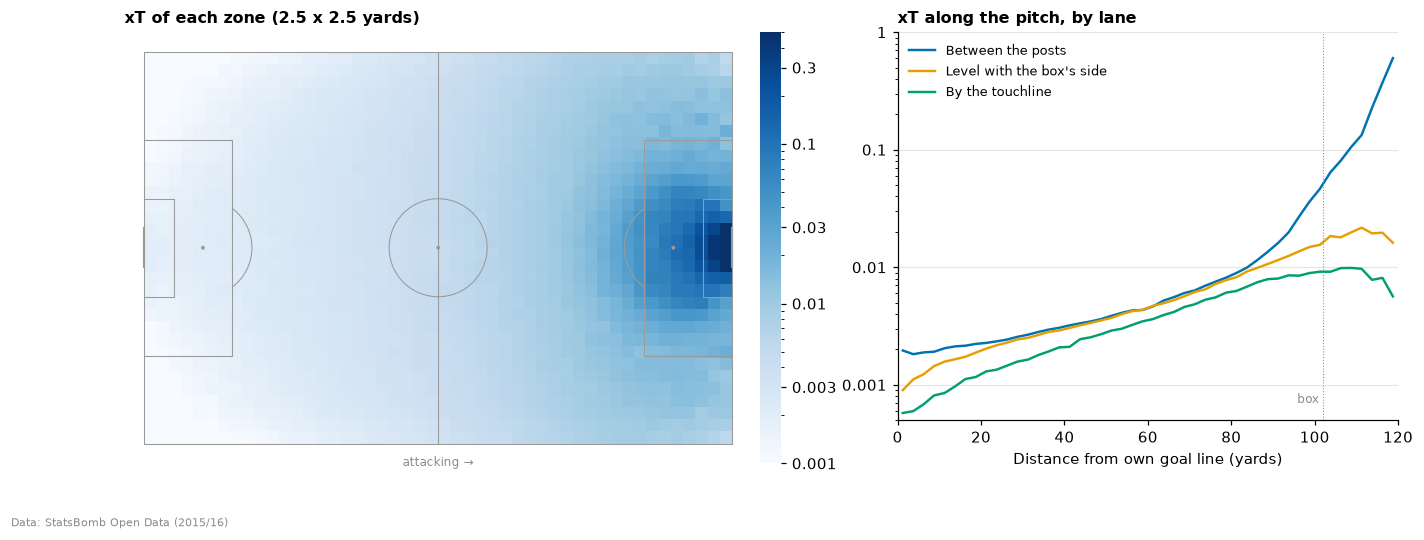

,xT
"Own penalty area (12, 40)",0.002
"Halfway line, centre (60, 40)",0.004
"30 yards out, centre (90, 40)",0.016
"Edge of the box, centre (102, 40)",0.046
"Wide, level with the box (108, 10)",0.015
"Penalty spot (108, 40)",0.118
"Six-yard box, centre (115, 40)",0.434


In [7]:
fig = plt.figure(figsize=(13, 4.9))
ax_map = fig.add_axes([0.0, 0.08, 0.55, 0.8])
ax_line = fig.add_axes([0.63, 0.16, 0.35, 0.72])
stat = pitch.bin_statistic(actions.x, actions.y, statistic="count", bins=(NX, NY))
stat["statistic"] = xt_map
pitch.draw(ax=ax_map)
mesh = pitch.heatmap(stat, ax=ax_map, cmap="Blues", norm=LogNorm(0.001, 0.5), edgecolors="none")
bar = fig.colorbar(mesh, ax=ax_map, fraction=0.03, pad=0.01)
bar.set_ticks([0.001, 0.003, 0.01, 0.03, 0.1, 0.3])
bar.set_ticklabels(["0.001", "0.003", "0.01", "0.03", "0.1", "0.3"])
bar.outline.set_visible(False)
ax_map.set_title(f"xT of each zone ({LENGTH / NX:.1f} x {WIDTH / NY:.1f} yards)", fontsize=10.5)
ax_map.text(60, 82.5, "attacking →", ha="center", va="top", fontsize=8, color=GREY)
x = stat["cx"][0]
lanes = {
    "Between the posts": (36, 44),
    "Level with the box's side": (18, 22),
    "By the touchline": (0, 5),
}
for (name, (lo, hi)), color in zip(lanes.items(), OKABE_ITO, strict=False):
    rows_in = (stat["cy"][:, 0] > lo) & (stat["cy"][:, 0] < hi)
    ax_line.plot(x, xt_map[rows_in].mean(axis=0), color=color, lw=1.6, label=name)
ax_line.set(
    yscale="log", xlim=(0, 120), ylim=(0.0005, 1), xlabel="Distance from own goal line (yards)",
)  # fmt: skip
ax_line.set_yticks([0.001, 0.01, 0.1, 1], labels=["0.001", "0.01", "0.1", "1"])
ax_line.axvline(102, color=GREY, lw=0.7, ls=":")
ax_line.text(101, 0.0007, "box", ha="right", fontsize=8, color=GREY)
ax_line.set_title("xT along the pitch, by lane", fontsize=10.5)
ax_line.legend(loc="upper left", fontsize=8.5)
credit(fig, STATSBOMB)
plt.show()

spots = {
    "Own penalty area (12, 40)": (12, 40),
    "Halfway line, centre (60, 40)": (60, 40),
    "30 yards out, centre (90, 40)": (90, 40),
    "Edge of the box, centre (102, 40)": (102, 40),
    "Wide, level with the box (108, 10)": (108, 10),
    "Penalty spot (108, 40)": (108, 40),
    "Six-yard box, centre (115, 40)": (115, 40),
}
xs, ys = np.array(list(spots.values())).T
display(
    pd.DataFrame({"xT": value_at(xt_map, xs, ys)}, index=list(spots))
    .style.format("{:.3f}")
    .set_caption("xT at a few spots (StatsBomb coordinates, yards)")
)

### What section 1 shows

- **The map.** Having the ball is worth little until the last third of the pitch: 0.002 in the own
  box, 0.004 at the centre spot, 0.016 thirty yards out. Then it climbs: 0.046 at the edge of the
  box, 0.118 on the penalty spot, 0.43 in the middle of the six-yard box. Wide areas stay low
  (0.015 by the touchline, level with the box). A move is worth the xT it gains.
- **Losses count.** The textbook model, which sees only shots and moves, overstates what
  possessions lead to by 46%. Counting dispossessions, miscontrols and failed dribbles as the
  end of a chain brings it within 13% and lifts its held-out skill to that of the zone average.
  It halves the worth of the build-up against the final third, but hardly changes the order of
  moves.
- **Zones of 2.5 yards** predict held-out matches best (finer zones add nothing), and a move's
  credit is nearly the same from either half of the matches (0.988).
- **One map** fits both wings and all four leagues. La Liga's chains reach 6% more xG from the
  same zones and Ligue 1's 6% less, a gap that belongs to the players rather than the zones.
  Shots are valued by their xG: goals give the same map with more noise.
- **Next:** each player's xT per 90 from passes and carries, how reliable it is, how much it
  depends on possession and the team, what it adds to the profiles, and how failed moves count
  against a player.

## 2. Each player's xT

A player's xT adds up what their moves gain on the map of section 1: a pass from a zone worth
0.016 to one worth 0.046 gains 0.03. Three ways of counting it differ in what a player is charged
for (`analysis.xt`):

- **gained**: the gains of successful passes and carries; a move to a zone worth less counts 0,
  as a failed pass does;
- **net**: gains less losses (Singh's player xT): a pass back costs the xT it gives up;
- **charged**: net, less the xT of the zone where the player gave the ball away, with a failed
  pass or a ball loss (dispossessed, a miscontrol, a failed dribble). The map discounts every
  zone for the chance of losing the ball there; this version charges the player who loses it.

Each is split into passes and carries, per 90 minutes. Shots are left out: a player's own shots
are worth their xG, already in the profiles. Players are those with a profile (outfield players
with 900 minutes, or 450 if under 23; notebook 02).

In [8]:
pool = pool_player_seasons(con, cfg, age_on=cfg.backtest.market_view)
players = compared_players(pool, cfg).set_index("player_id")
players["comparison_group"] = players.comparison_group.astype(str)
OUTFIELD = list(cfg.profiles)
players = players[players.comparison_group.isin(OUTFIELD)]
names = con.sql("SELECT player_id, coalesce(player_nickname, player_name) AS name FROM players")
players["name"] = names.df().set_index("player_id").name.reindex(players.index)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
COLORS = position_colors(cfg)
GROUP_COLORS = {g: COLORS["W" if g == "AMW" else g] for g in OUTFIELD}

# Every player-match played, with the credit of the player's moves (0 without any).
KEYS = ["match_id", "team_id", "player_id"]
played = con.sql("""
    SELECT pm.match_id, pm.team_id, pm.player_id, pm.seconds_played / 60 AS minutes
    FROM player_matches pm JOIN matches m USING (match_id)
    WHERE m.scouting_pool AND pm.played
""").df()
credit_sums = played.merge(
    player_match_credit(xt_map, actions), on=KEYS, how="left", validate="1:1"
).fillna(0.0)
SUMS = [c for c in credit_sums.columns if c not in KEYS]
season = credit_rates(credit_sums.groupby("player_id")[SUMS].sum().loc[players.index])
regulars = players[players.minutes >= cfg.compared.minutes]
print(
    f"{len(players):,} players with a profile ({len(regulars):,} with 900+ minutes): "
    + ", ".join(
        f"{GROUP_NAMES[g].lower()} {n}"
        for g, n in players.comparison_group.value_counts()[OUTFIELD].items()
    )
    + "."
)

1,335 players with a profile (1,266 with 900+ minutes): centre-backs 265, full-backs 267, central midfielders 321, attacking midfielders and wingers 305, centre-forwards 177.


### 2.1 Three ways to count

Is a season of each version enough to tell players apart? Reliability as in notebook 02: for the
players with 1,800 minutes or more, 50 random splits of their matches into two halves of 900
minutes, and the correlation between the halves' rates (centred within league) within each
comparison group. K = 900 (1 − r) / r is the number of minutes at which a rate is half signal,
half noise; the profiles keep statistics with r of 0.4 or more.

In [9]:
METRICS = [
    *(f"{v}{part}" for v in CREDITS for part in ("", "_passes", "_carries")),
    "passes_failed",
    "lost",
]
ROW_LABELS = {
    "gained": "Gained", "gained_passes": "Gained: passes", "gained_carries": "Gained: carries",
    "net": "Net", "net_passes": "Net: passes", "net_carries": "Net: carries",
    "charged": "Charged", "charged_passes": "Charged: passes, less failed passes",
    "charged_carries": "Charged: carries, less balls lost",
    "passes_failed": "Given away: failed passes", "lost": "Given away: balls lost",
}  # fmt: skip
long_season = players[players.minutes >= 2 * RELIABILITY_MINUTES]
r900, used = {}, {}
for g in OUTFIELD:
    sub = long_season[long_season.comparison_group == g]
    curve = split_half_reliability(
        credit_sums[credit_sums.player_id.isin(sub.index)],
        sub.league,
        METRICS,
        [RELIABILITY_MINUTES],
        columns=SUMS,
        rate_fn=credit_rates,
    )
    r900[GROUP_NAMES[g]], used[g] = curve[METRICS].mean(), curve.players.mean()
r900 = pd.DataFrame(r900)
print(
    "Players with 900 minutes in both halves (mean of 50 draws): "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n:.0f}" for g, n in used.items())
    + "."
)
display(
    r900.rename(index=ROW_LABELS)
    .style.format("{:.2f}")
    .map(lambda v: f"color: {GREY}" if v < 0.4 else "")
    .set_caption("Reliability at 900 minutes, per 90 xT, by comparison group (grey: below 0.4)")
)
k = RELIABILITY_MINUTES * (1 - r900.loc[list(CREDITS)]) / r900.loc[list(CREDITS)]
display(
    k.rename(index=ROW_LABELS)
    .style.format("{:,.0f}")
    .set_caption("K: minutes at which each version is half signal, half noise")
)

Players with 900 minutes in both halves (mean of 50 draws): centre-backs 172, full-backs 137, central midfielders 186, attacking midfielders and wingers 127, centre-forwards 79.


,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
Gained,0.59,0.55,0.72,0.75,0.67
Gained: passes,0.52,0.43,0.64,0.62,0.51
Gained: carries,0.69,0.80,0.82,0.84,0.71
Net,0.54,0.50,0.65,0.71,0.60
Net: passes,0.49,0.39,0.59,0.59,0.44
Net: carries,0.48,0.70,0.70,0.79,0.60
Charged,0.38,0.30,0.45,0.49,0.54
"Charged: passes, less failed passes",0.34,0.21,0.38,0.40,0.34
"Charged: carries, less balls lost",0.13,0.32,0.39,0.45,0.47
Given away: failed passes,0.33,0.62,0.70,0.65,0.60


,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
Gained,621,746,350,306,438
Net,755,905,481,360,592
Charged,"1,489","2,062","1,111",922,779


In [10]:
rows = {}
for g in OUTFIELD:
    s = season.loc[regulars.index[regulars.comparison_group == g]]
    rho = s[list(CREDITS)].corr("spearman")
    rows[GROUP_NAMES[g]] = {
        "Gained vs net": rho.loc["gained", "net"],
        "Net vs charged": rho.loc["net", "charged"],
        "Gained vs charged": rho.loc["gained", "charged"],
        "Net vs xT given away": s.net.corr(s.passes_failed + s.lost, method="spearman"),
        "Gained given back by moves backwards": ((s.gained - s.net) / s.gained).median(),
    }
agreement = pd.DataFrame(rows).T
display(
    agreement.style.format("{:.2f}")
    .format("{:.0%}", subset="Gained given back by moves backwards")
    .set_caption(
        "Players with 900+ minutes: Spearman correlations between the versions and between net xT "
        "and the xT given away; median share of the xT gained that moves backwards give back"
    )
)
for g in ("CM", "CF"):
    s = season.loc[regulars.index[regulars.comparison_group == g]]
    pct = s[["gained", "net"]].rank(pct=True) * 100
    drop = (pct.gained - pct.net).nlargest(5).index
    print(
        f"{GROUP_NAMES[g]}, furthest down from gained to net (percentile in the group): "
        + "; ".join(f"{players.name[i]} {pct.gained[i]:.0f} to {pct.net[i]:.0f}" for i in drop)
        + "."
    )

,Gained vs net,Net vs charged,Gained vs charged,Net vs xT given away,Gained given back by moves backwards
Centre-backs,0.97,0.72,0.69,0.28,20%
Full-backs,0.99,0.73,0.68,0.68,14%
Central midfielders,0.97,0.51,0.42,0.59,32%
Attacking midfielders and wingers,0.97,0.70,0.66,0.57,24%
Centre-forwards,0.91,0.59,0.44,0.27,48%


Central midfielders, furthest down from gained to net (percentile in the group): Marouane Fellaini 32 to 1; Matías Vecino 48 to 24; Vincent Koziello 50 to 27; Andy King 22 to 1; Marco Parolo 51 to 30.
Centre-forwards, furthest down from gained to net (percentile in the group): Romelu Lukaku 66 to 27; Christian Benteke 52 to 13; Junior Tallo 50 to 14; Lewis Grabban 51 to 16; Olivier Giroud 56 to 22.


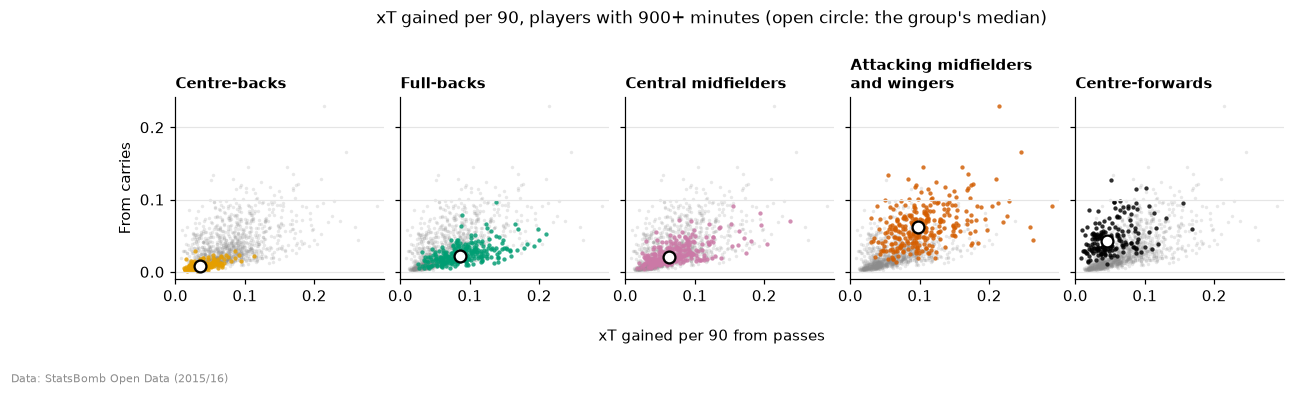

,Passes,Carries,Total,Carries' share
Centre-backs,0.035,0.008,0.043,18%
Full-backs,0.086,0.022,0.112,20%
Central midfielders,0.063,0.020,0.085,24%
Attacking midfielders and wingers,0.098,0.062,0.158,39%
Centre-forwards,0.045,0.043,0.089,48%


In [11]:
reg = season.loc[regulars.index].join(regulars.comparison_group)
fig, axes = plt.subplots(1, len(OUTFIELD), figsize=(13, 3.3), sharex=True, sharey=True)
for ax, g in zip(axes, OUTFIELD, strict=True):
    own = reg[reg.comparison_group == g]
    ax.scatter(reg.gained_passes, reg.gained_carries, s=5, color=GREY, alpha=0.2, lw=0)
    ax.scatter(own.gained_passes, own.gained_carries, s=8, color=GROUP_COLORS[g], alpha=0.8, lw=0)
    ax.scatter(
        own.gained_passes.median(), own.gained_carries.median(), s=60, facecolor="white",
        edgecolor="black", lw=1.5, zorder=3,
    )  # fmt: skip
    ax.set_title(GROUP_NAMES[g].replace(" and ", "\nand "), fontsize=10)
    ax.set_xticks([0, 0.1, 0.2])
axes[0].set(xlim=(0, 0.3), ylabel="From carries")
fig.supxlabel("xT gained per 90 from passes", fontsize=10, y=0.06)
fig.suptitle(
    "xT gained per 90, players with 900+ minutes (open circle: the group's median)", fontsize=11
)
fig.subplots_adjust(bottom=0.24, top=0.74, wspace=0.08)
credit(fig, STATSBOMB)
plt.show()

medians = reg.groupby("comparison_group")[["gained_passes", "gained_carries", "gained"]].median()
medians["carries' share"] = medians.gained_carries / medians.gained
medians = medians.loc[OUTFIELD].rename(index=GROUP_NAMES).rename_axis(index=None)
medians.columns = ["Passes", "Carries", "Total", "Carries' share"]
display(
    medians.style.format("{:.3f}")
    .format("{:.0%}", subset="Carries' share")
    .set_caption("xT gained per 90, median player with 900+ minutes")
)

In [12]:
top = {}
for g in OUTFIELD:
    best = season.loc[regulars.index[regulars.comparison_group == g], "gained"].nlargest(10)
    top[GROUP_NAMES[g]] = [f"{players.name[i]} ({v:.3f})" for i, v in best.items()]
display(
    pd.DataFrame(top, index=range(1, 11)).style.set_caption(
        "Highest xT gained per 90 in each group, players with 900+ minutes (as recorded, before "
        "any adjustment)"
    )
)

,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
1,Simon Francis (0.135),Alex Sandro (0.261),James Rodríguez (0.307),Neymar (0.444),Luis Suárez (0.250)
2,Nikola Maksimović (0.115),Maicon (0.257),Javier Pastore (0.275),Lionel Messi (0.412),Antonio Cassano (0.227)
3,Javier Mascherano (0.114),Dani Alves (0.244),Santi Cazorla (0.261),Ángel Di María (0.381),Hatem Ben Arfa (0.218)
4,Mathieu Bodmer (0.109),Juan Cuadrado (0.234),Isco (0.247),Gerard Deulofeu (0.338),Zlatan Ibrahimović (0.205)
5,Juan Jesus (0.104),Marcelo (0.231),Abdelaziz Barrada (0.243),Alexis Sánchez (0.326),Lucas Pérez (0.201)
6,Nenad Tomović (0.096),Daniel Carvajal (0.229),Cesc Fàbregas (0.223),Mesut Özil (0.320),Alassane Pléa (0.198)
7,Daley Blind (0.095),Antonio Valencia (0.228),Andrés Iniesta (0.221),Lorenzo Insigne (0.308),Paulo Dybala (0.195)
8,Cesare Bovo (0.095),Christophe Jallet (0.221),James Milner (0.219),Burgui (0.307),Stevan Jovetić (0.184)
9,Giorgio Chiellini (0.087),Fábio Coentrão (0.211),Marek Hamšík (0.218),Alessandro Diamanti (0.306),Sergio Agüero (0.179)
10,Mattia Cassani (0.087),Benjamin Mendy (0.198),Jordan Henderson (0.200),Dries Mertens (0.305),Rodrigo Palacio (0.176)


### What 2.1 shows

- **xT gained is the most reliable of the three in every group:** 0.55 to 0.75 at 900 minutes
  (K of 306 to 746 minutes), against 0.50 to 0.71 for net xT. Carries are more reliable than
  passes in every version.
- **Gained and net rank players almost the same** (Spearman 0.97 to 0.99; 0.91 among
  centre-forwards). They part on moves backwards, which give back a fifth of the xT a
  centre-back gains, a third of a central midfielder's and half of a centre-forward's. Net xT
  sinks the forwards who hold the ball up and lay it off: Lukaku from the 66th percentile of
  centre-forwards to the 27th, Benteke from the 52nd to the 13th, Giroud from the 56th to the
  22nd; Fellaini from the 32nd to the 1st among central midfielders. The map values zones, not
  the pressure a lay-off escapes, so it cannot tell a lay-off that keeps the ball from one that
  wastes a chance; xT gained counts both as 0.
- **Charging the ball given away halves the reliability:** 0.30 to 0.54 (K of 779 to 2,062
  minutes), below 0.4 among centre-backs and full-backs. What a player gives away rises with
  what they make (Spearman 0.27 to 0.68): players who try more lose more, and the difference
  cancels much of what tells them apart. Each part is reliable on its own outside centre-backs,
  and the profiles already read that side through pass completion and ball losses per touch.
- **xT differs by role.** The median full-back gains more than the median central midfielder
  (0.112 per 90 against 0.085); centre-backs gain least (0.043), attacking midfielders and
  wingers most (0.158). Carries bring 18% of a centre-back's xT and 48% of a centre-forward's.
- **The leaders are the expected names:** Neymar, Messi and Di María; James Rodríguez, Pastore
  and Cazorla; Suárez, Cassano and Ben Arfa; Alex Sandro, Maicon and Dani Alves. Most play for
  teams that keep the ball, which section 2.2 measures.
- **A player's xT is the xT gained** by their successful passes and carries, per 90 minutes
  (`xt.credit` in the config).

### 2.2 Possession and the team

A player can only pass and carry while the team has the ball, and notebook 02 (section 2) found
the counts made with the ball growing faster than the time with it. Possession is measured as
there: the team's share of the time with the ball while the player is on the pitch (gaps
between events capped at 10 seconds; `analysis.possession`). Three questions, for xT gained:

- how much it grows with possession **within players**, from the same player's matches with more
  or less of the ball (Poisson regression with a fixed effect per player and minutes as
  exposure; the slope is an elasticity, 1 when xT grows in proportion to the time with the ball);
- which adjustment to an even share of possession takes it out best: none, in proportion to the
  time (rate × 0.5 / share) or by the measured elasticity (rate × (0.5 / share)^elasticity), the
  one the profiles use. Each is judged within comparison group on what is left of the
  correlation with possession, how much the team explains beyond chance (rates relative to the
  group's average in the player's league, as in notebook 02), the reliability at 900 minutes
  (the adjustment applied to each half) and how much the order of players changes;
- whether the leagues differ once players are compared within their group.

Players with 900+ minutes; the reliability, as in 2.1, on those with 1,800+.

In [13]:
poss_sums = credit_sums.merge(player_possession(con), on=KEYS, how="left", validate="1:1")
poss_sums["gained"] = poss_sums.passes_gained + poss_sums.carries_gained
poss_sums["with"] = poss_sums.own_seconds / (poss_sums.own_seconds + poss_sums.opp_seconds)
# Robustness: the share without the player's own time on the ball.
own_rest = poss_sums.own_seconds - poss_sums.self_own_seconds
opp_rest = poss_sums.opp_seconds - poss_sums.self_opp_seconds
poss_sums["with_rest"] = own_rest / (own_rest + opp_rest)
PARTS = {"gained": "Total", "passes_gained": "Passes", "carries_gained": "Carries"}
rows = []
for g in OUTFIELD:
    sub = poss_sums[poss_sums.player_id.isin(regulars.index[regulars.comparison_group == g])]
    for part in PARTS:
        beta, se = elasticity(sub, part, "with")
        rows.append({
            "group": g, "part": part, "beta": beta, "se": se,
            "without own time": elasticity(sub, part, "with_rest")[0],
            "45+ minutes": elasticity(sub[sub.minutes >= 45], part, "with")[0],
        })  # fmt: skip
xt_elasticities = pd.DataFrame(rows)
for check in ["without own time", "45+ minutes"]:
    change = xt_elasticities[check] - xt_elasticities.beta
    print(
        f"{check.capitalize()}: elasticities change by a median of {change.median():+.2f} "
        f"(largest {change.abs().max():.2f})."
    )
shown = xt_elasticities.assign(
    value=[
        f"{b:.2f} ± {1.96 * s:.2f}"
        for b, s in zip(xt_elasticities.beta, xt_elasticities.se, strict=True)
    ]
).pivot(index="group", columns="part", values="value")
display(
    shown.loc[OUTFIELD, list(PARTS)]
    .rename(index=GROUP_NAMES, columns=PARTS)
    .rename_axis(index=None, columns=None)
    .style.set_caption(
        "Elasticity of xT gained to the team's share of possession, within players (95% interval; "
        "players with 900+ minutes, all their matches)"
    )
)

Without own time: elasticities change by a median of -0.10 (largest 0.17).
45+ minutes: elasticities change by a median of +0.02 (largest 0.07).


,Total,Passes,Carries
Centre-backs,1.81 ± 0.16,1.70 ± 0.18,2.29 ± 0.19
Full-backs,1.50 ± 0.13,1.60 ± 0.15,1.17 ± 0.13
Central midfielders,1.53 ± 0.11,1.62 ± 0.13,1.29 ± 0.12
Attacking midfielders and wingers,0.95 ± 0.11,1.16 ± 0.15,0.61 ± 0.10
Centre-forwards,0.47 ± 0.16,0.70 ± 0.25,0.23 ± 0.17


**A defender's or central midfielder's xT grows faster than the time with the ball**
(elasticity 1.50 to 1.81): with a tenth more of the ball, the same player gains 15% to 19% more
xT. That is faster than their open-play passes (1.06 to 1.41 in notebook 02) and about as fast
as their progressive passes (1.23 to 1.48): a team with more of the ball has it higher up the
pitch, where moves gain more, against an opponent sitting deeper. Centre-backs' carries go
furthest (2.29). Further forward the dependence fades: about in proportion for attacking
midfielders and wingers (0.95), half of it for centre-forwards (0.47), whose carries (0.23)
barely depend on it. Leaving the player's own time on the ball out of the share lowers the
elasticities by about 0.1; matches of 45 minutes or more change them little.

In [14]:
BETA = xt_elasticities.set_index(["group", "part"]).beta
RATE_OF = {"gained": "gained", "passes_gained": "gained_passes", "carries_gained": "gained_carries"}
ADJUSTMENTS = {
    "none": "As recorded", "proportional": "In proportion to the time",
    "elasticity": "Measured elasticity",
}  # fmt: skip


def adjusted_xt(r: pd.DataFrame, share: pd.Series, g: str, how: str) -> pd.DataFrame:
    """xT gained per 90 and its parts, on an even share of possession."""
    out = r[list(RATE_OF.values())].copy()
    for part, m in RATE_OF.items():
        b = {"none": 0.0, "proportional": 1.0, "elasticity": BETA[(g, part)]}[how]
        out[m] = adjust(r[m], share, b)
    return out


def relative(values: pd.Series) -> pd.Series:
    """Rates over the average of the player's comparison group and league."""
    keys = [players.comparison_group.reindex(values.index), players.league.reindex(values.index)]
    return values / values.groupby(keys).transform("mean")


POSS_SUMS = [*SUMS, "own_seconds", "opp_seconds"]
season_sums = poss_sums.groupby("player_id")[POSS_SUMS].sum().loc[players.index]
share = season_sums.own_seconds / (season_sums.own_seconds + season_sums.opp_seconds)
main_team = (
    credit_sums.groupby(["player_id", "team_id"]).minutes.sum().reset_index()
    .sort_values(["minutes", "team_id"]).groupby("player_id").tail(1)
    .set_index("player_id").team_id
)  # fmt: skip
rows, adjusted_season = [], {}
for g in OUTFIELD:
    ids = regulars.index[regulars.comparison_group == g]
    sub = long_season[long_season.comparison_group == g]
    for how in ADJUSTMENTS:
        values = adjusted_xt(season.loc[ids], share.loc[ids], g, how)
        adjusted_season[(g, how)] = values
        rel = relative(values.gained)
        reliability = split_half_reliability(
            poss_sums[poss_sums.player_id.isin(sub.index)],
            sub.league,
            ["gained"],
            [RELIABILITY_MINUTES],
            columns=POSS_SUMS,
            rate_fn=lambda s, g=g, how=how: adjusted_xt(
                credit_rates(s), s.own_seconds / (s.own_seconds + s.opp_seconds), g, how
            ),
        ).gained.mean()
        rows.append({
            "group": GROUP_NAMES[g], "adjustment": ADJUSTMENTS[how],
            "With possession": rel.corr(share.loc[ids], method="spearman"),
            "Team share": team_effect(
                pd.DataFrame({"rel": rel, "team": main_team.reindex(ids), "group": g}), "rel"
            ),
            "Reliability": reliability,
            "Same order as recorded": values.gained.corr(
                season.loc[ids, "gained"], method="spearman"
            ),
        })  # fmt: skip
xt_adjustments = pd.DataFrame(rows)
table = xt_adjustments.pivot(index="group", columns="adjustment").reindex(
    [GROUP_NAMES[g] for g in OUTFIELD]
)
table = table.reindex(columns=list(ADJUSTMENTS.values()), level="adjustment")
display(
    table.rename_axis(index=None, columns=[None, None])
    .style.format("{:.2f}")
    .set_caption(
        "xT gained per 90, players with 900+ minutes: Spearman correlation with possession and "
        "team share (beyond chance) of the rate relative to the group's league average, "
        "reliability at 900 minutes, Spearman with the rate as recorded"
    )
)

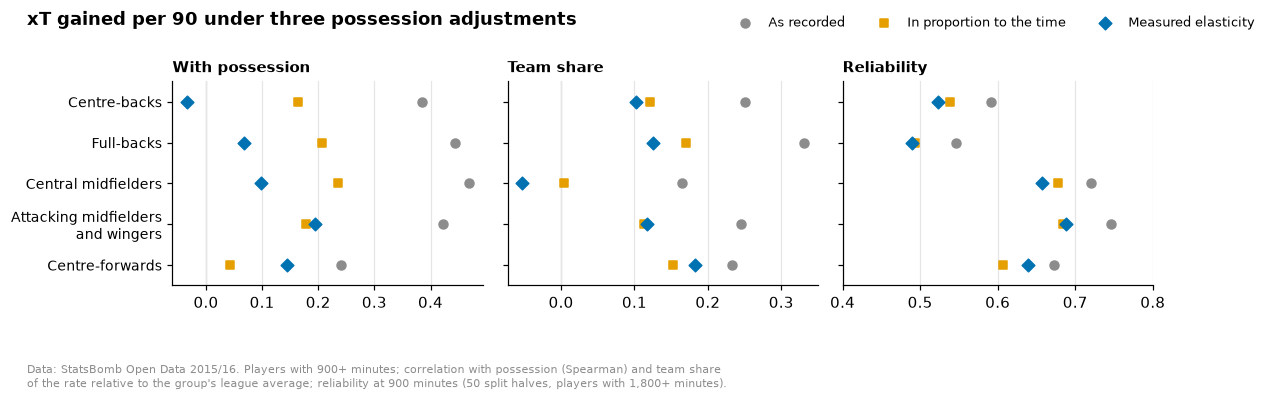

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.2), sharey=True)
ys = np.arange(len(OUTFIELD))
markers = dict(zip(ADJUSTMENTS.values(), ["o", "s", "D"], strict=True))
colors = dict(zip(ADJUSTMENTS.values(), [GREY, OKABE_ITO[1], OKABE_ITO[0]], strict=True))
for ax, criterion in zip(axes, ["With possession", "Team share", "Reliability"], strict=True):
    for label in ADJUSTMENTS.values():
        d = xt_adjustments[xt_adjustments.adjustment == label].set_index("group")
        ax.scatter(
            d[criterion].reindex([GROUP_NAMES[g] for g in OUTFIELD]), ys, s=34,
            marker=markers[label], color=colors[label], label=label, zorder=3,
        )  # fmt: skip
    ax.axvline(0, color="#BBBBBB", lw=0.8, zorder=0)
    ax.set_title(criterion, fontsize=10)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ys, [GROUP_NAMES[g].replace(" and ", "\nand ") for g in OUTFIELD], fontsize=9)
axes[0].set_ylim(len(OUTFIELD) - 0.5, -0.5)
axes[2].set_xlim(0.4, 0.8)
fig.legend(
    *axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, fontsize=8.5, frameon=False,
    bbox_to_anchor=(0.99, 1.0),
)  # fmt: skip
fig.suptitle(
    "xT gained per 90 under three possession adjustments", x=0.01, ha="left", fontweight="bold"
)
fig.subplots_adjust(top=0.78, bottom=0.2, wspace=0.08)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Players with 900+ minutes; correlation with possession "
    "(Spearman) and team share\nof the rate relative to the group's league average; reliability "
    "at 900 minutes (50 split halves, players with 1,800+ minutes).",
)
plt.show()

**As recorded, xT gained goes with possession** (Spearman 0.24 to 0.47 within group), and the
team explains 17% to 33% of it beyond chance. **The measured elasticity** takes most of that
out: correlation with possession -0.03 to 0.19, team share at most 0.18, at a cost of 0.03 to
0.07 in reliability, since possession, the same in both halves of a player's season, was part
of what made it stable. **In proportion to the time** leaves more of the possession among
defenders and central midfielders (0.16 to 0.24) and takes out more than the within-player
effect among centre-forwards (0.04 against 0.14). What remains after the measured elasticity,
mostly among attacking midfielders and wingers (0.19), is the part time with the ball cannot
separate: better players at the teams that keep it.

In [16]:
rng = np.random.default_rng(2016)
eta, gaps = {}, {}
for how in ("none", "elasticity"):
    d = pd.concat(
        [adjusted_season[(g, how)].assign(group=g, league=players.league) for g in OUTFIELD]
    )
    # Chance: the same players with their leagues shuffled within each group.
    null = [
        league_effect(
            d.assign(league=d.groupby("group").league.transform(rng.permutation)), "gained"
        )["partial η²"]
        for _ in range(200)
    ]
    eta[ADJUSTMENTS[how]] = (league_effect(d, "gained")["partial η²"], np.quantile(null, 0.95))
    for g in OUTFIELD:
        dg = d[d.group == g]
        gaps[(ADJUSTMENTS[how], GROUP_NAMES[g])] = (
            dg.groupby("league").gained.mean() / dg.gained.mean() - 1
        )
print(
    "Partial η² of league once the group is known: "
    + "; ".join(
        f"{k.lower()} {v:.3f} (shuffled leagues, 95th percentile {q:.3f})"
        for k, (v, q) in eta.items()
    )
    + "."
)
display(
    pd.DataFrame(gaps)
    .T[LEAGUES]
    .rename_axis(columns=None)
    .style.format("{:+.1%}")
    .set_caption(
        "xT gained per 90 by league, players with 900+ minutes: each league's mean against the "
        "group's mean"
    )
)

Partial η² of league once the group is known: as recorded 0.008 (shuffled leagues, 95th percentile 0.006); measured elasticity 0.013 (shuffled leagues, 95th percentile 0.006).


In [17]:
top, movers = {}, []
for g in OUTFIELD:
    after = adjusted_season[(g, "elasticity")].gained
    best = after.nlargest(10)
    top[GROUP_NAMES[g]] = [f"{players.name[i]} ({v:.3f})" for i, v in best.items()]
    pct = pd.DataFrame({"before": season.loc[after.index, "gained"], "after": after}).rank(pct=True)
    change = (pct.after - pct.before) * 100
    for i in [*change.nlargest(3).index, *change.nsmallest(3).index]:
        movers.append({
            "Group": GROUP_NAMES[g], "Player": players.name[i], "Team's possession": share[i],
            "Percentile as recorded": 100 * pct.before[i], "Adjusted": 100 * pct.after[i],
        })  # fmt: skip
display(
    pd.DataFrame(top, index=range(1, 11)).style.set_caption(
        "Highest xT gained per 90 after the measured elasticity, players with 900+ minutes"
    )
)
display(
    pd.DataFrame(movers)
    .style.format(
        {"Team's possession": "{:.0%}", "Percentile as recorded": "{:.0f}", "Adjusted": "{:.0f}"}
    )
    .hide(axis="index")
    .set_caption("The three players who move most up and down in each group, in percentile")
)

,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
1,Simon Francis (0.125),Maicon (0.216),James Rodríguez (0.242),Neymar (0.348),Luis Suárez (0.222)
2,Nikola Maksimović (0.120),Ali Adnan (0.207),Santi Cazorla (0.215),Burgui (0.328),Antonio Cassano (0.221)
3,Cesare Bovo (0.100),Alex Sandro (0.205),Abdelaziz Barrada (0.197),Lionel Messi (0.320),Lucas Pérez (0.207)
4,Cristian Zaccardo (0.097),Jeffrey Schlupp (0.202),Javier Pastore (0.195),Alessandro Diamanti (0.315),Hatem Ben Arfa (0.207)
5,Mathieu Bodmer (0.093),Daryl Janmaat (0.199),Cesc Fàbregas (0.193),Gerard Deulofeu (0.313),Alassane Pléa (0.188)
6,Mattia Cassani (0.091),Andrea Rispoli (0.197),Isco (0.192),Ángel Di María (0.303),Jamie Vardy (0.187)
7,Russell Martin (0.088),Gaetano Letizia (0.194),James Milner (0.189),Dušan Tadić (0.300),Paulo Dybala (0.184)
8,Juanfran (0.088),Fábio Coentrão (0.194),Alfred Duncan (0.187),Riyad Mahrez (0.290),Zlatan Ibrahimović (0.183)
9,Antoine Conte (0.085),Bruno Peres (0.192),Aaron Ramsey (0.169),Alexis Sánchez (0.285),Stevan Jovetić (0.175)
10,Felipe (0.084),Juan Cuadrado (0.189),Panagiotis Tachtsidis (0.169),Mesut Özil (0.285),Sergio Agüero (0.170)


Group,Player,Team's possession,Percentile as recorded,Adjusted
Centre-backs,Sebastián Coates,41%,38,75
Centre-backs,Syam Ben Youssef,38%,55,92
Centre-backs,Romain Thomas,43%,41,72
Centre-backs,Mapou Yanga-Mbiwa,60%,70,35
Centre-backs,Gonzalo Rodríguez,59%,71,38
Centre-backs,Gerard Piqué,65%,95,64
Full-backs,Chris Brunt,42%,46,77
Full-backs,Craig Dawson,42%,45,73
Full-backs,Daniel Pavlovic,42%,43,71
Full-backs,Gregory van der Wiel,63%,75,36


### What 2.2 shows

- **xT depends on possession more than most counts.** Within players, a defender's or central
  midfielder's xT grows 1.5 to 1.8 times as fast as the time with the ball, an attacking
  midfielder's or winger's about in proportion (0.95), a centre-forward's half as fast (0.47).
  As recorded, it correlates with possession at 0.24 to 0.47 within group, and the team explains
  17% to 33% of it.
- **The measured elasticity takes most of it out**, as it does for the profiles: correlation with
  possession -0.03 to 0.19, team share at most 0.18, for 0.03 to 0.07 of reliability (0.49 to
  0.69 at 900 minutes, above 0.4 in every group). In proportion to the time leaves more of the
  possession among defenders and central midfielders and takes out too much among
  centre-forwards.
- **The order changes where possession is far from even.** Piqué goes from the 95th percentile
  of centre-backs to the 64th, Jordi Alba from the 87th to the 48th of full-backs, Busquets from
  the 60th to the 22nd of central midfielders (Barcelona had 65% of the ball); Coates, at
  Sunderland (42%), from the 38th to the 75th. Mahrez and Vardy, at Leicester (44%), join the
  top ten of their groups.
- **The leagues barely differ** once players are compared within group: the league explains
  1.3% of the variation after the adjustment (0.8% as recorded), beyond chance (0.6%) but far
  below fouls won and times dribbled past (6%, notebook 02). Serie A's players gain 4% to 9%
  more than their group's average, except centre-forwards; Ligue 1's attacking midfielders and
  wingers 8% less. The four leagues stay on one scale, as in the profiles.
- **A player's xT is put on an even share of possession by its elasticity within the comparison
  group**, like the profiles' per-90 statistics. Section 2.3 asks what it adds to them.

### 2.3 What xT adds to the profiles

xT gained weighs a player's passes and carries by where they take the ball. Several profile
statistics already count those moves by where they go: progressive passes and carries, passes
into the box, key passes, crosses. Does xT tell something about a player that the twelve
statistics of the group's profile do not? Three tests within each comparison group, on the
numbers as the profiles use them (adjusted for recording context and possession; xT as in 2.2),
players with 900+ minutes:

- **similarity:** the Spearman correlation of xT with each profile statistic. The profiles admit
  no two statistics correlated at 0.8 or more (notebook 02, section 1.4);
- **how much of xT the profile predicts:** a linear regression of xT on the group's twelve
  statistics, R² out of sample (10-fold cross-validation);
- **whether the rest is the player:** the reliability at 900 minutes, as in 2.1, of xT less the
  profile's prediction (the regression fitted on the season, applied to each half). If that part
  is stable, xT measures something the profile misses; if it is noise, xT repeats the profile.
  The same test on each profile statistic, against the other eleven, is the yardstick: what a
  statistic already in the profile adds to the rest.

In [18]:
profile_values = con.sql("SELECT * FROM profile_values").df()
profile_statistics = con.sql("SELECT * FROM profile_statistics").df()
adjusted = profile_values.pivot(index="player_id", columns="statistic", values="adjusted")
xt_adjusted = pd.concat([adjusted_season[(g, "elasticity")].gained for g in OUTFIELD])
similar, close = {}, []
for g in OUTFIELD:
    ids = regulars.index[regulars.comparison_group == g]
    rho = adjusted.loc[ids, list(cfg.profiles[g])].corrwith(xt_adjusted.loc[ids], method="spearman")
    rho = rho.sort_values(key=abs, ascending=False)
    similar[GROUP_NAMES[g]] = [f"{LABELS[m]} ({v:.2f})" for m, v in rho.head(4).items()]
    close += [
        f"{GROUP_NAMES[g].lower()}, {LABELS[m].lower()} {v:.2f}"
        for m, v in rho.items()
        if abs(v) >= 0.8
    ]
print("At 0.8 or more: " + "; ".join(close) + ".")
display(
    pd.DataFrame(similar, index=range(1, 5)).style.set_caption(
        "The four profile statistics closest to xT gained in each group (Spearman, players with "
        "900+ minutes)"
    )
)

At 0.8 or more: full-backs, completed passes into the box 0.87.


,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
1,Progressive passes (zones) (0.76),Completed passes into the box (0.87),Key passes (open play) (0.74),Completed passes into the box (0.72),Completed passes into the box (0.74)
2,Progressive carries (zones) (0.56),Key passes (open play) (0.80),Progressive carries (zones) (0.60),Progressive carries (zones) (0.65),Dribbles attempted (0.55)
3,Open-play passes (0.50),Open-play crosses (0.70),Progressive passes (zones) (0.51),Key passes (open play) (0.64),Open-play passes (0.42)
4,Long passes (30+ yards) (0.41),Progressive carries (zones) (0.64),Non-penalty xG (0.35),Dribbles attempted (0.50),Aerial duels (-0.41)


In [19]:
CV = KFold(10, shuffle=True, random_state=2016)
CREDIT_SUMS = [c for c in SUMS if c != "minutes"]
COLUMNS = [*SUMMED, *POSSESSION, *CREDIT_SUMS]
# The matches of the players with 1,800+ minutes: the profile's counts, rescaled per recording
# context as in the profiles (`profile_recording`), with possession and the xT credit.
half_counts = player_match_counts(con).merge(
    poss_sums[[*KEYS, *POSSESSION, *CREDIT_SUMS]], on=KEYS, how="left", validate="1:1"
)
half_counts = half_counts[half_counts.player_id.isin(long_season.index)]
half_counts = rescale(
    half_counts, players.comparison_group, recording_context(half_counts, cfg),
    con.sql("SELECT * FROM profile_recording").df(),
)  # fmt: skip


def unique_parts(values: pd.DataFrame, models: dict) -> pd.DataFrame:
    """Each target less what the rest of the profile predicts of it."""
    return pd.DataFrame({t: values[t] - m.predict(values[rest]) for t, (rest, m) in models.items()})


rows, xt_predicted, refit = [], {}, []
for g in OUTFIELD:
    stats = list(cfg.profiles[g])
    targets = ["xt", *stats]
    ids = regulars.index[regulars.comparison_group == g]
    values = adjusted.loc[ids, stats].assign(xt=xt_adjusted.loc[ids])
    models, explained = {}, {}
    for t in targets:
        rest = [m for m in stats if m != t]
        models[t] = (rest, LinearRegression().fit(values[rest], values[t]))
        predicted = cross_val_predict(LinearRegression(), values[rest], values[t], cv=CV)
        explained[t] = 1 - np.var(values[t] - predicted) / np.var(values[t])
    xt_predicted[g] = pd.Series(
        cross_val_predict(LinearRegression(), values[stats], values.xt, cv=CV), index=ids
    )

    def half_rates(s: pd.DataFrame, g=g, stats=stats, models=models) -> pd.DataFrame:
        r = adjusted_rates(s, pd.Series(g, index=s.index), profile_statistics)[stats]
        r = r.fillna(r.groupby(level="half").transform("mean"))  # a ratio with no attempts
        r["xt"] = adjusted_xt(credit_rates(s), own_share(s), g, "elasticity").gained
        # Robustness: the regression refitted within each half.
        within = []
        for _, h in r.groupby(level="half"):
            refitted = {
                t: (rest, LinearRegression().fit(h[rest], h[t])) for t, (rest, _) in models.items()
            }
            within.append(unique_parts(h, refitted))
        r = r.join(unique_parts(r, models).add_prefix("unique_"))
        return r.join(pd.concat(within).add_prefix("within_"))

    sub = long_season[long_season.comparison_group == g]
    metrics = [*targets, *(f"{k}_{t}" for k in ("unique", "within") for t in targets)]
    r = split_half_reliability(
        half_counts[half_counts.player_id.isin(sub.index)], sub.league, metrics,
        [RELIABILITY_MINUTES], columns=COLUMNS, rate_fn=half_rates,
    )[metrics].mean()  # fmt: skip
    for t in targets:
        rows.append({
            "group": g, "statistic": t, "Reliability": r[t], "Explained by the rest": explained[t],
            "Unique part's reliability": r[f"unique_{t}"],
        })  # fmt: skip
        refit.append(r[f"within_{t}"] - r[f"unique_{t}"])
unique = pd.DataFrame(rows)
print(
    "Refitted within each half, the unique parts' reliability changes by a median of "
    f"{np.median(refit):+.2f} (from {min(refit):+.2f} to {max(refit):+.2f})."
)
xt_rows = unique[unique.statistic == "xt"].set_index("group")
others = unique[unique.statistic != "xt"].groupby("group")["Unique part's reliability"]
summary = pd.DataFrame({
    "Reliability": xt_rows.Reliability,
    "Explained by the profile": xt_rows["Explained by the rest"],
    "Unique part's reliability": xt_rows["Unique part's reliability"],
    "Profile statistics: median": others.median(),
    "lowest": others.min(),
    "highest": others.max(),
}).loc[OUTFIELD].rename(index=GROUP_NAMES)  # fmt: skip
below = unique.merge(
    xt_rows["Unique part's reliability"].rename("xt"), left_on="group", right_index=True
)
below = below[(below.statistic != "xt") & (below["Unique part's reliability"] < below.xt)]
print(
    "Profile statistics whose unique part is less reliable than xT's: "
    + "; ".join(
        f"{GROUP_NAMES[g].lower()}, {LABELS[m].lower()} {v:.2f}"
        for g, m, v in below[["group", "statistic", "Unique part's reliability"]].itertuples(
            index=False
        )
    )
    + "."
)
display(
    summary.rename_axis(index=None)
    .style.format("{:.2f}")
    .set_caption(
        "xT gained per 90, players with 900+ minutes: reliability at 900 minutes, R² out of "
        "sample on the group's twelve profile statistics, reliability of the part they do not "
        "predict; the same for each profile statistic against the other eleven"
    )
)

Refitted within each half, the unique parts' reliability changes by a median of +0.02 (from -0.05 to +0.09).
Profile statistics whose unique part is less reliable than xT's: central midfielders, key passes (open play) 0.26; central midfielders, ball losses per touch 0.28; central midfielders, tackles 0.25; centre-forwards, completed passes into the box 0.13.


,Reliability,Explained by the profile,Unique part's reliability,Profile statistics: median,lowest,highest
Centre-backs,0.52,0.67,0.10,0.45,0.17,0.53
Full-backs,0.49,0.87,-0.02,0.42,0.15,0.54
Central midfielders,0.66,0.73,0.28,0.44,0.25,0.63
Attacking midfielders and wingers,0.69,0.83,0.16,0.46,0.26,0.61
Centre-forwards,0.64,0.69,0.24,0.40,0.13,0.70


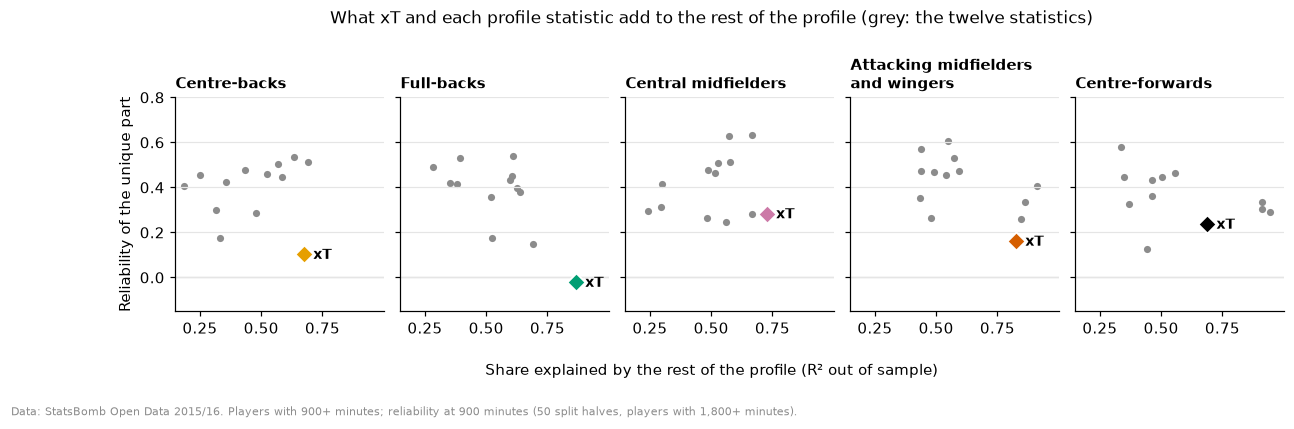

In [20]:
fig, axes = plt.subplots(1, len(OUTFIELD), figsize=(13, 3.6), sharex=True, sharey=True)
for ax, g in zip(axes, OUTFIELD, strict=True):
    d = unique[unique.group == g].set_index("statistic")
    stats = d.drop(index="xt")
    ax.scatter(
        stats["Explained by the rest"], stats["Unique part's reliability"], s=22, color=GREY, lw=0
    )
    ax.scatter(
        d.loc["xt", "Explained by the rest"], d.loc["xt", "Unique part's reliability"], s=70,
        marker="D", color=GROUP_COLORS[g], edgecolor="white", lw=1.2, zorder=3,
    )  # fmt: skip
    ax.annotate(
        "xT", (d.loc["xt", "Explained by the rest"], d.loc["xt", "Unique part's reliability"]),
        xytext=(6, -3), textcoords="offset points", fontsize=9, fontweight="bold",
    )  # fmt: skip
    ax.axhline(0, color="#BBBBBB", lw=0.8, zorder=0)
    ax.set_title(GROUP_NAMES[g].replace(" and ", "\nand "), fontsize=10)
    ax.set_xticks([0.25, 0.5, 0.75])
axes[0].set(xlim=(0.15, 1.0), ylim=(-0.15, 0.8), ylabel="Reliability of the unique part")
fig.supxlabel("Share explained by the rest of the profile (R² out of sample)", fontsize=10, y=0.05)
fig.suptitle(
    "What xT and each profile statistic add to the rest of the profile (grey: the twelve "
    "statistics)", fontsize=11,
)  # fmt: skip
fig.subplots_adjust(bottom=0.22, top=0.76, wspace=0.08)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Players with 900+ minutes; reliability at 900 minutes "
    "(50 split halves, players with 1,800+ minutes).",
)
plt.show()

**The profile predicts most of xT:** 67% of it among centre-backs to 87% among full-backs, out
of sample. The closest statistics are the ones that count moves by where they go: progressive
passes among centre-backs (0.76), key passes among central midfielders (0.74), completed passes
into the box further forward (0.72 to 0.87). Among full-backs xT and passes into the box
correlate at 0.87, past the profiles' limit of 0.8, and key passes follow at 0.795.

**What the profile misses is mostly noise.** The part of xT the twelve statistics do not predict
has a reliability of -0.02 (full-backs) to 0.28 (central midfielders) at 900 minutes, against a
median of 0.40 to 0.46 for what each profile statistic adds to the other eleven. Only four of the
60 profile statistics add less than xT in their group: key passes, tackles and ball losses per touch
among central midfielders (0.25 to 0.28) and passes into the box among centre-forwards (0.13).
Refitting the regression within each half changes these numbers little (median +0.02). What xT
weighs beyond those counts, how much more a move into one zone is worth than into another, does
not tell players apart over a season.

In [21]:
gaps = []
for g in OUTFIELD:
    ids = regulars.index[regulars.comparison_group == g]
    d = pd.DataFrame({"xt": xt_adjusted.loc[ids], "predicted": xt_predicted[g]})
    pct = d.rank(pct=True) * 100
    gap = pct.xt - pct.predicted
    for i in [*gap.nlargest(2).index, *gap.nsmallest(2).index]:
        gaps.append({
            "Group": GROUP_NAMES[g], "Player": players.name[i], "xT gained per 90": d.xt[i],
            "Predicted by the profile": d.predicted[i], "Percentile: xT": pct.xt[i],
            "predicted": pct.predicted[i],
        })  # fmt: skip
display(
    pd.DataFrame(gaps)
    .style.format("{:.3f}", subset=["xT gained per 90", "Predicted by the profile"])
    .format("{:.0f}", subset=["Percentile: xT", "predicted"])
    .hide(axis="index")
    .set_caption(
        "The two players in each group furthest above and below the xT their profile predicts "
        "(out of sample), players with 900+ minutes"
    )
)

Group,Player,xT gained per 90,Predicted by the profile,Percentile: xT,predicted
Centre-backs,Iván Ramis,0.077,0.036,93,25
Centre-backs,Molla Wagué,0.071,0.040,89,38
Centre-backs,Timm Klose,0.038,0.060,37,87
Centre-backs,Mathieu Peybernes,0.029,0.049,15,65
Full-backs,Francisco Molinero,0.142,0.097,77,32
Full-backs,Martín Montoya,0.118,0.086,57,20
Full-backs,Lorenzo De Silvestri,0.106,0.133,43,70
Full-backs,Patrice Evra,0.096,0.121,33,59
Central midfielders,Ivaylo Chochev,0.146,0.082,93,38
Central midfielders,Sami Khedira,0.127,0.082,84,39


### What 2.3 shows

- **xT mostly repeats the profile.** The twelve statistics of each group predict 67% to 87% of
  it out of sample, through the ones that count moves by where they go: progressive passes and
  carries, passes into the box, key passes.
- **What it adds is not stable over a season.** The part the profile misses has a reliability of
  -0.02 to 0.28 at 900 minutes, below what almost every profile statistic adds to the rest
  (median 0.40 to 0.46). The players furthest from what their profile predicts, Iván Ramis among
  centre-backs or Joel Campbell among attacking midfielders and wingers, are there mostly by
  chance.
- **Among full-backs xT is a second count of passes into the box** (Spearman 0.87, past the
  profiles' limit of 0.8), and a more reliable one (0.49 against 0.40 at 900 minutes). Key
  passes, the full-backs' least reliable statistic (0.35), follow at 0.795.
- **Whether xT takes a place in the profiles**, and in place of which statistic, is weighed in
  section 4, with an expected pass completion (section 3).